<a href="https://colab.research.google.com/github/AngelikaBaloy/DS4002-Project2-Group5/blob/main/Airline_Project_Analysis_INPROGRESS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS4002 - Group 5 - Project 2: Analysis

Group members: Angelika Baloy, Samuel Bromberg, Inmar Chavarria

## IAD Flight Departure Delay Rates

Packages

In [1]:
#All Packages Needed
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

2024 Data

In [2]:
#Data Merging & Cleaning for 2024

united = pd.read_csv("IAD_2024_United.csv", skiprows=7, usecols=range(17))
american = pd.read_csv("IAD_2024_American.csv", skiprows=7, usecols=range(17))
delta = pd.read_csv("IAD_2024_Delta.csv", skiprows=7, usecols=range(17))

#combine datasets
flights_2024 = pd.concat([united, american, delta], ignore_index=True)    #THIS IS THE NEW COMBINED DATASET

# Remove source information and empty rows
flights_2024 = flights_2024[
    flights_2024["Carrier Code"].isin(["UA", "AA", "DL"])
].copy()

# Convert date to datetime
flights_2024["Date (MM/DD/YYYY)"] = pd.to_datetime(flights_2024["Date (MM/DD/YYYY)"])

#check combined dataset
print(flights_2024.shape)
print(flights_2024["Carrier Code"].value_counts())


(36215, 17)
Carrier Code
UA    32249
DL     3225
AA      741
Name: count, dtype: int64


In [3]:
#if you need to save the combined 2024 dataset, run this.
flights_2024.to_csv("IAD_2024_Combined.csv", index=False)

2025 Data

In [4]:
#Data Merging & Cleaning for 2025

united = pd.read_csv("IAD_2025_United.csv", skiprows=7, usecols=range(17))
american = pd.read_csv("IAD_2025_American.csv", skiprows=7, usecols=range(17))
delta = pd.read_csv("IAD_2025_Delta.csv", skiprows=7, usecols=range(17))

#combine datasets
flights_2025 = pd.concat([united, american, delta], ignore_index=True)       #NEW COMBINED 2025 DATASET

#Remove source information and empty rows
flights_2025 = flights_2025[flights_2025["Carrier Code"].isin(["UA", "AA", "DL"])].copy()

# Convert date to datetime
flights_2025["Date (MM/DD/YYYY)"] = pd.to_datetime(flights_2025["Date (MM/DD/YYYY)"])

#check the combined dataset
print(flights_2025.shape)
print(flights_2025["Carrier Code"].value_counts())


(39140, 17)
Carrier Code
UA    35159
DL     2948
AA     1033
Name: count, dtype: int64


In [5]:
#if you need to save the combined 2025 dataset, run this.
flights_2025.to_csv("IAD_2025_Combined.csv", index=False)

Exploratory Data Analysis

In [6]:
flights_2024["Year"] = 2024
flights_2025["Year"] = 2025

# Combine datasets for EDA
flights = pd.concat([flights_2024, flights_2025], ignore_index=True)   #combines the two combined datasets (2024 and 2025)

# Convert variables
flights["Date (MM/DD/YYYY)"] = pd.to_datetime(flights["Date (MM/DD/YYYY)"])

flights["Departure delay (Minutes)"] = pd.to_numeric(flights["Departure delay (Minutes)"],errors="coerce")

flights = flights.dropna(subset=["Date (MM/DD/YYYY)", "Departure delay (Minutes)"]).copy()

# Create variables
flights["Delayed"] = (flights["Departure delay (Minutes)"] >= 15).astype(int)

flights["Month"] = flights["Date (MM/DD/YYYY)"].dt.month
flights["Quarter"] = flights["Date (MM/DD/YYYY)"].dt.quarter
flights["Day of Week"] = flights["Date (MM/DD/YYYY)"].dt.day_name()

# Airline colors
airline_colors = {"UA": "royalblue", "AA": "firebrick","DL": "forestgreen"}

airline_names = {"UA": "United","AA": "American","DL": "Delta"}

weekdays = ["Monday", "Tuesday", "Wednesday""Thursday", "Friday", "Saturday", "Sunday"]

sns.set_theme(style="whitegrid")



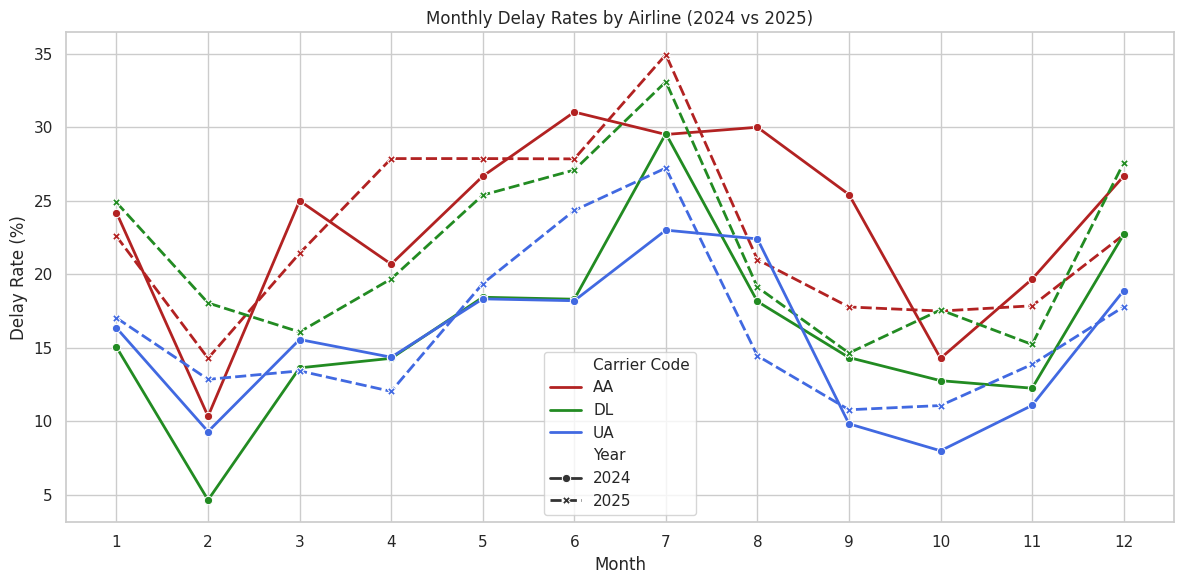

In [7]:
monthly_airline = (
    flights.groupby(["Year", "Month", "Carrier Code"])["Delayed"]
    .mean()
    .mul(100)
    .reset_index(name="Delay Rate")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_airline,
    x="Month",
    y="Delay Rate",
    hue="Carrier Code",
    style="Year",
    palette=airline_colors,
    markers=True,
    dashes=True,
    linewidth=2
)

plt.title("Monthly Delay Rates by Airline (2024 vs 2025)")
plt.xlabel("Month")
plt.ylabel("Delay Rate (%)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()



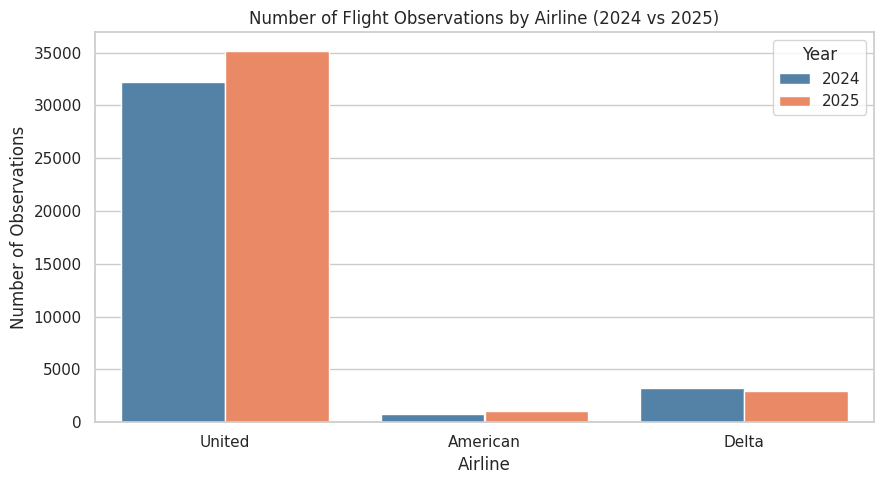

In [8]:
# Bar graph
plt.figure(figsize=(9, 5))

sns.countplot(
    data=flights,
    x="Carrier Code",
    hue="Year",
    order=["UA", "AA", "DL"],
    palette=["steelblue", "coral"]
)

plt.title("Number of Flight Observations by Airline (2024 vs 2025)")
plt.xlabel("Airline")
plt.ylabel("Number of Observations")
plt.xticks([0, 1, 2], ["United", "American", "Delta"])
plt.legend(title="Year")
plt.tight_layout()
plt.show()


## ARIMA Analysis

In [13]:
# train: 2024
# test: 2025 (but not all of it)

# Packages required for analysis
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller




In [11]:
data = pd.read_csv("IAD_2024_Combined.csv")
print(data)

      Carrier Code Date (MM/DD/YYYY)  Flight Number Tail Number  \
0               UA        2024-01-01          204.0      N850UA   
1               UA        2024-01-01          213.0      N818UA   
2               UA        2024-01-01          277.0      N57864   
3               UA        2024-01-01          326.0      N17316   
4               UA        2024-01-01          345.0      N76055   
...            ...               ...            ...         ...   
36210           DL        2024-12-31         1084.0      N312DU   
36211           DL        2024-12-31         1354.0      N318DU   
36212           DL        2024-12-31         1400.0      N993AT   
36213           DL        2024-12-31         1444.0      N945AT   
36214           DL        2024-12-31         1695.0      N955AT   

      Destination Airport Scheduled departure time Actual departure time  \
0                     SRQ                    09:00                 08:57   
1                     RDU                  

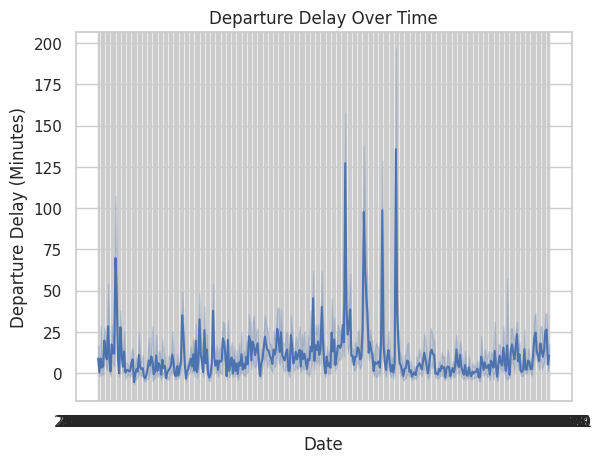

In [15]:
sns.lineplot(x="Date (MM/DD/YYYY)", y="Departure delay (Minutes)", data=data)
plt.title("Departure Delay Over Time")
plt.xlabel("Date")
plt.ylabel("Departure Delay (Minutes)")
plt.show()

In [14]:
# checking for stationarity
result = adfuller(data['Departure delay (Minutes)'])
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])
# if p > .05, the data are non-stationary

ADF Statistic: -15.469548
p-value: 0.000000


/tmp/ipykernel_1871/1660335524.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(data['Departure delay (Minutes)'])


In [16]:
# creating model - departure delay (minutes)
model = ARIMA(data['Departure delay (Minutes)'], order=(1, 1, 1))
model_fit = model.fit()
print(model_fit.summary())

                                   SARIMAX Results                                   
Dep. Variable:     Departure delay (Minutes)   No. Observations:                36215
Model:                        ARIMA(1, 1, 1)   Log Likelihood             -192780.916
Date:                       Wed, 21 Oct 2026   AIC                         385567.832
Time:                               17:32:50   BIC                         385593.323
Sample:                                    0   HQIC                        385575.938
                                     - 36215                                         
Covariance Type:                         opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0038      0.003     -1.142      0.253      -0.010       0.003
ma.L1         -0.9722      0.001  -1473.369      0.000      -0.974      -0.

In [17]:
# predictions
predictions = model_fit.forecast(steps=len(data))
print(predictions)

36215    13.332235
36216    13.237003
36217    13.237361
36218    13.237360
36219    13.237360
           ...    
72425    13.237360
72426    13.237360
72427    13.237360
72428    13.237360
72429    13.237360
Name: predicted_mean, Length: 36215, dtype: float64


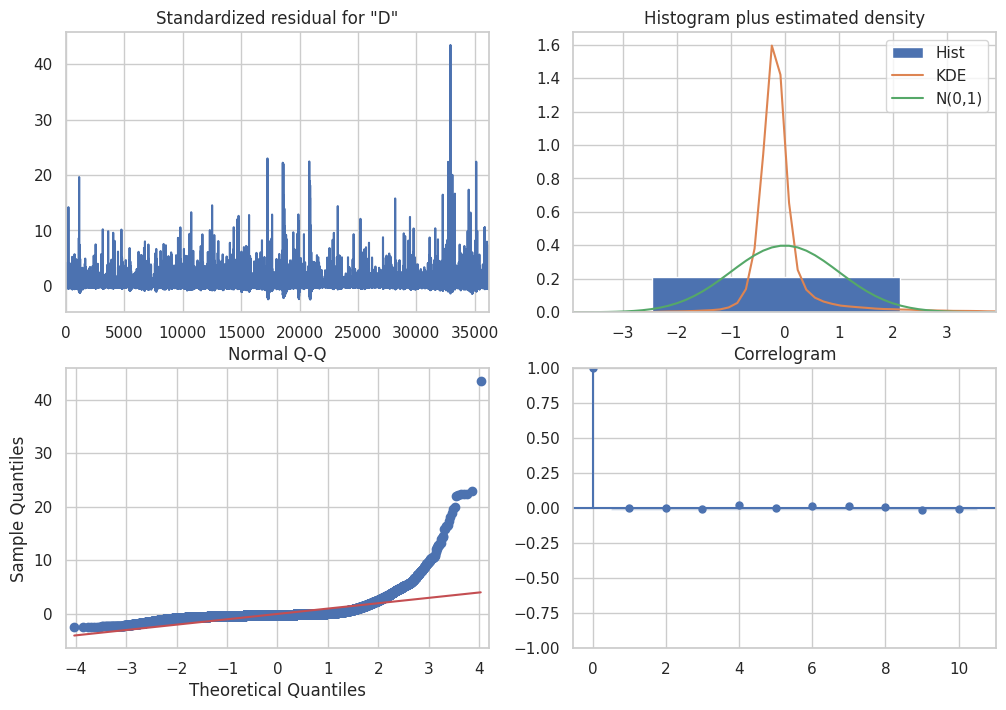

In [18]:
# checking residuals
model_fit.plot_diagnostics(figsize=(12, 8))
plt.show()

In [21]:
# predicting percentage of delayed flights per day


data["Date (MM/DD/YYYY)"] = pd.to_datetime(data["Date (MM/DD/YYYY)"])
data["Departure delay (Minutes)"] = pd.to_numeric(data["Departure delay (Minutes)"], errors="coerce")
data["Delayed"] = (data["Departure delay (Minutes)"] >= 15).astype(int)

# Group by the correct date column name
daily_airline = data.groupby(["Date (MM/DD/YYYY)"])['Delayed'].mean() * 100
print(daily_airline)

Date (MM/DD/YYYY)
2024-01-01    14.606742
2024-01-02     6.593407
2024-01-03     8.888889
2024-01-04    15.555556
2024-01-05    10.000000
                ...    
2024-12-27    21.568627
2024-12-28    28.125000
2024-12-29    41.836735
2024-12-30    13.725490
2024-12-31    27.835052
Name: Delayed, Length: 366, dtype: float64


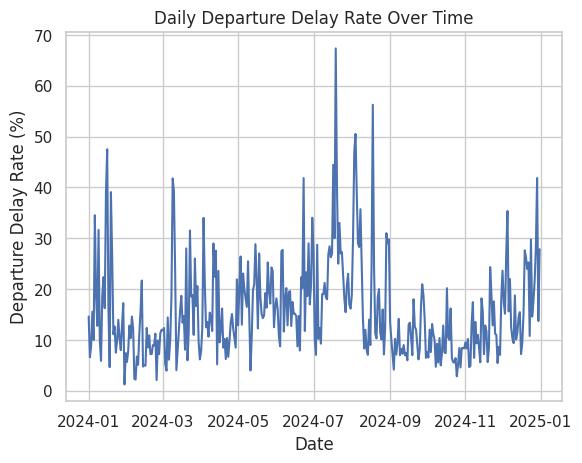

In [23]:
# plot
sns.lineplot(data=daily_airline.reset_index(), x="Date (MM/DD/YYYY)", y="Delayed")
plt.title("Daily Departure Delay Rate Over Time")
plt.xlabel("Date")
plt.ylabel("Departure Delay Rate (%)")
plt.show()

In [26]:
# checking for stationarity
result = adfuller(daily_airline)
print('ADF Statistic: %f' % result[0])
print('p-value: %f' % result[1])
# if p > .05, the data are non-stationary: looks like this is non-stationary

ADF Statistic: -2.528084
p-value: 0.108790


/tmp/ipykernel_1871/3042017221.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(daily_airline)


In [27]:
# differencing
daily_airline_diff = daily_airline.diff().dropna()

In [28]:
# creating model - daily departure delay rates (>15 min)
model = ARIMA(daily_airline_diff, order=(1, 1, 1))
model_fit = model.fit()
print(model_fit.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                Delayed   No. Observations:                  365
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -1316.381
Date:                Wed, 21 Oct 2026   AIC                           2638.762
Time:                        17:53:47   BIC                           2650.453
Sample:                    01-02-2024   HQIC                          2643.408
                         - 12-31-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3211      0.036     -8.943      0.000      -0.391      -0.251
ma.L1         -0.9999      3.450     -0.290      0.772      -7.762       5.762
sigma2        79.5987    274.013      0.290      0.7

In [29]:
# predictions
predictions = model_fit.forecast(steps= len(daily_airline_diff))
print(predictions)

2025-01-01   -4.487657
2025-01-02    1.483455
2025-01-03   -0.433723
2025-01-04    0.181836
2025-01-05   -0.015805
                ...   
2025-12-27    0.032230
2025-12-28    0.032230
2025-12-29    0.032230
2025-12-30    0.032230
2025-12-31    0.032230
Freq: D, Name: predicted_mean, Length: 365, dtype: float64


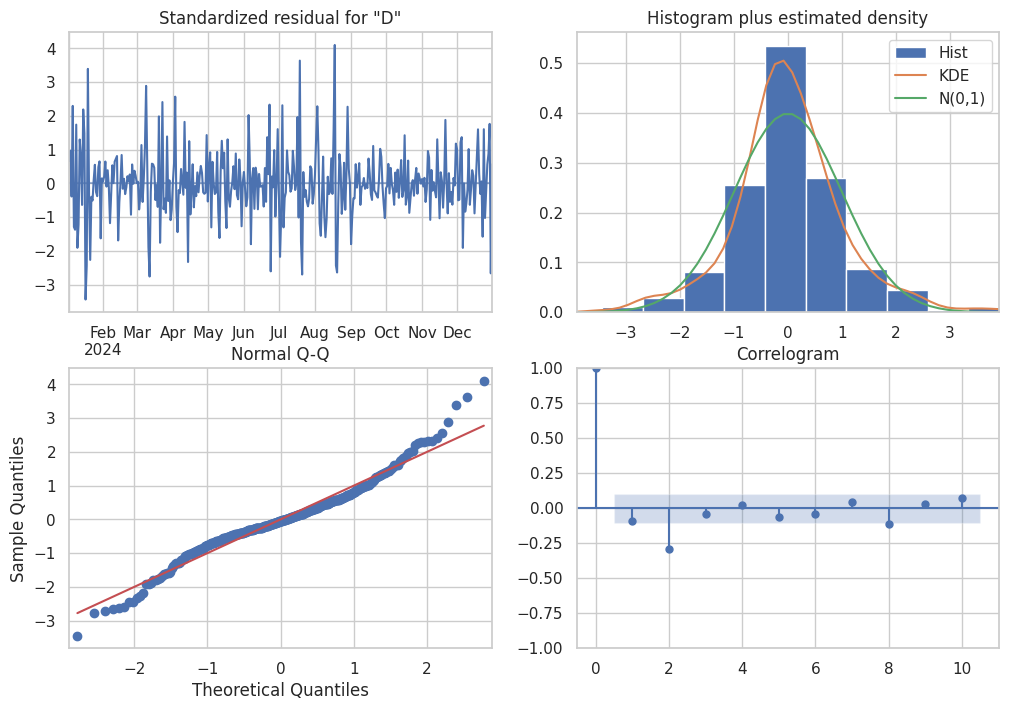

In [30]:
# residuals
model_fit.plot_diagnostics(figsize=(12, 8))
plt.show()